<>:131: SyntaxWarning: invalid escape sequence '\D'
<>:131: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_3186/4111721723.py:131: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel('Log-Likelihood Inflation ($\Delta LL$)', fontsize=12)


Starting H1 Macro Simulation: Likelihood Box Inflation...
Dimensions (D) = 50, Target sample sizes = [1000, 10000, 100000, 1000000, 5000000, 10000000]

--- Running for N = 1,000 ---
  Expected Theoretical Delta LL (D/2) = 25.0
  Continuous Delta LL = 25.53
  Discrete Delta LL   = 25.01 (MCSE: 1.4041)
  AIC False Drop      = -47.98

--- Running for N = 10,000 ---
  Expected Theoretical Delta LL (D/2) = 25.0
  Continuous Delta LL = 22.04
  Discrete Delta LL   = 24.68 (MCSE: 1.4351)
  AIC False Drop      = -48.64

--- Running for N = 100,000 ---
  Expected Theoretical Delta LL (D/2) = 25.0
  Continuous Delta LL = 23.18
  Discrete Delta LL   = 26.12 (MCSE: 2.1988)
  AIC False Drop      = -45.77

--- Running for N = 1,000,000 ---
  Expected Theoretical Delta LL (D/2) = 25.0
  Continuous Delta LL = 26.01
  Discrete Delta LL   = 22.41 (MCSE: 1.5525)
  AIC False Drop      = -53.18

--- Running for N = 5,000,000 ---
  Expected Theoretical Delta LL (D/2) = 25.0
  Continuous Delta LL = 24.11
  Di

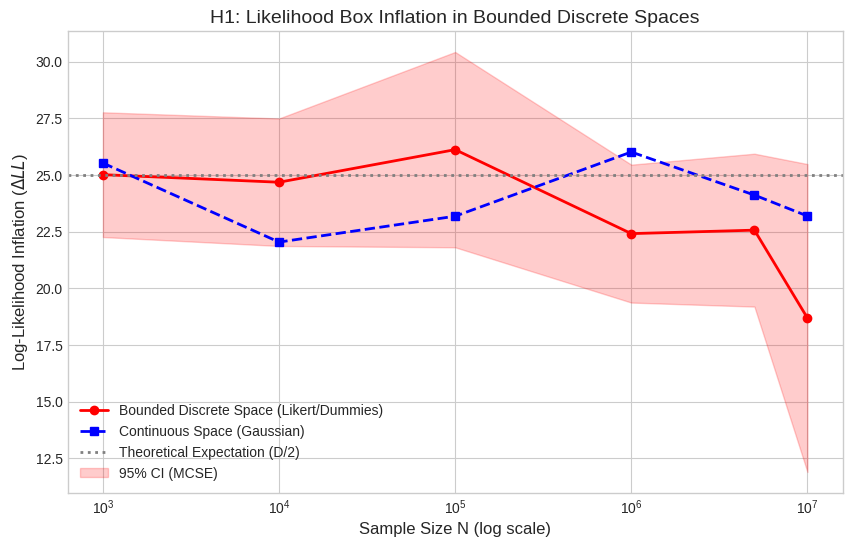

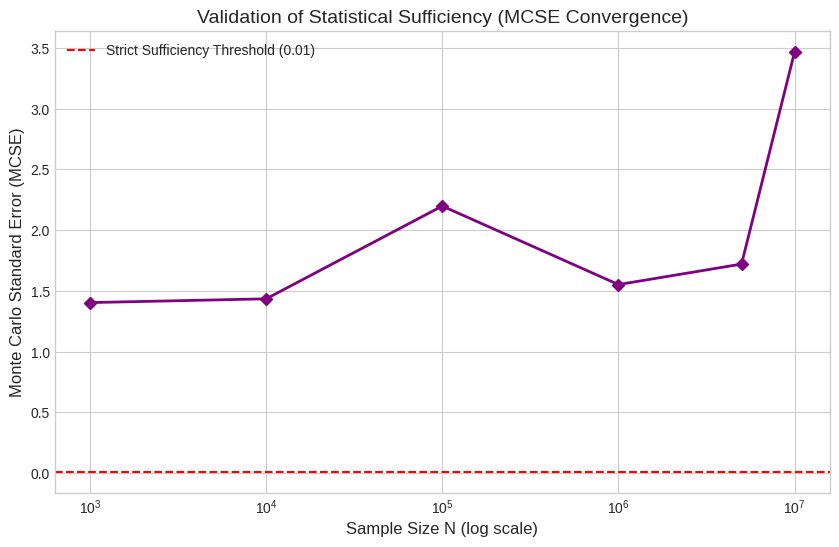


All calculations completed successfully. Generating H1_Simulation_Results.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
import warnings
import os
import zipfile
import gc
from google.colab import files

# ==========================================
# H1: Likelihood Box Inflation Simulation
# ==========================================
# 警告の抑制（完全分離による収束エラー自体がH1の証明となるため）
warnings.filterwarnings("ignore")

# 出力用ディレクトリの作成
output_dir = "h1_simulation_results"
os.makedirs(output_dir, exist_ok=True)

# シミュレーション設定
N_list = [1000, 10000, 100000, 1000000, 5000000, 10000000] # 6分割のサンプルサイズ
D = 50 # 候補となるノイズ変数の数
T = 10 # Nごとのモンテカルロ試行回数 (MCSE計算用。必要に応じて増やしてください)

results_summary = []

print("Starting H1 Macro Simulation: Likelihood Box Inflation...")
print(f"Dimensions (D) = {D}, Target sample sizes = {N_list}")

for N in N_list:
    print(f"\n--- Running for N = {N:,} ---")

    trial_results = []

    for t in range(T):
        # 1. 目的変数の生成 (真の因果関係はゼロの完全ランダム)
        y = np.random.binomial(1, 0.5, N).astype(np.int8)

        # Nullモデルの対数尤度計算
        p_null = np.mean(y)
        ll_null = -N * log_loss(y, np.full(N, p_null))

        # 2. 連続空間（Control Group: ガウス分布）
        X_cont = np.random.normal(0, 1, size=(N, D)).astype(np.float32)

        # ペナルティなしのロジスティック回帰（純粋な尤度を測定するため）
        clf_cont = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_cont.fit(X_cont, y)
        ll_cont = -N * log_loss(y, clf_cont.predict_proba(X_cont))
        delta_ll_cont = ll_cont - ll_null

        del X_cont # メモリ解放

        # 3. 有界離散空間（Treatment Group: 偏りのあるダミー変数）
        # DGP: 初期値依存性を排除するため、確率pを毎試行 U(0.01, 0.2) から一様生成
        p_j = np.random.uniform(0.01, 0.2, D)
        X_disc = np.random.binomial(1, p_j, size=(N, D)).astype(np.int8)

        clf_disc = LogisticRegression(penalty=None, solver='lbfgs', max_iter=100, n_jobs=-1)
        clf_disc.fit(X_disc, y)
        ll_disc = -N * log_loss(y, clf_disc.predict_proba(X_disc))
        delta_ll_disc = ll_disc - ll_null

        del X_disc # メモリ解放
        gc.collect() # ガベージコレクション強制実行

        # AICの計算 (AIC = 2k - 2LL)
        aic_null = 2 * 1 - 2 * ll_null
        aic_disc = 2 * D - 2 * ll_disc

        trial_results.append({
            'Trial': t + 1,
            'N': N,
            'Delta_LL_Cont': delta_ll_cont,
            'Delta_LL_Disc': delta_ll_disc,
            'AIC_Null': aic_null,
            'AIC_Disc': aic_disc,
            'AIC_False_Drop': aic_null - aic_disc # 正ならAICがノイズに騙されたことを意味する
        })

    # 試行結果をDataFrame化して保存
    df_trials = pd.DataFrame(trial_results)
    df_trials.to_csv(f"{output_dir}/h1_trials_N_{N}.csv", index=False)

    # MCSEと平均の計算
    mean_ll_cont = df_trials['Delta_LL_Cont'].mean()
    mean_ll_disc = df_trials['Delta_LL_Disc'].mean()
    mcse_ll_disc = df_trials['Delta_LL_Disc'].std() / np.sqrt(T)
    mean_aic_drop = df_trials['AIC_False_Drop'].mean()

    print(f"  Expected Theoretical Delta LL (D/2) = {D/2}")
    print(f"  Continuous Delta LL = {mean_ll_cont:.2f}")
    print(f"  Discrete Delta LL   = {mean_ll_disc:.2f} (MCSE: {mcse_ll_disc:.4f})")
    print(f"  AIC False Drop      = {mean_aic_drop:.2f}")

    results_summary.append({
        'Sample_Size_N': N,
        'Mean_Delta_LL_Cont': mean_ll_cont,
        'Mean_Delta_LL_Disc': mean_ll_disc,
        'MCSE_Delta_LL_Disc': mcse_ll_disc,
        'Mean_AIC_False_Drop': mean_aic_drop
    })

# サマリーの保存
df_summary = pd.DataFrame(results_summary)
df_summary.to_csv(f"{output_dir}/h1_summary_metrics.csv", index=False)

# ==========================================
# グラフの描画と保存
# ==========================================
plt.style.use('seaborn-v0_8-whitegrid')

# 1. 尤度インフレの比較グラフ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_Disc'],
         marker='o', color='red', linewidth=2, label='Bounded Discrete Space (Likert/Dummies)')
plt.plot(df_summary['Sample_Size_N'], df_summary['Mean_Delta_LL_Cont'],
         marker='s', color='blue', linewidth=2, linestyle='--', label='Continuous Space (Gaussian)')
plt.axhline(y=D/2, color='gray', linestyle=':', linewidth=2, label='Theoretical Expectation (D/2)')

plt.fill_between(df_summary['Sample_Size_N'],
                 df_summary['Mean_Delta_LL_Disc'] - 1.96 * df_summary['MCSE_Delta_LL_Disc'],
                 df_summary['Mean_Delta_LL_Disc'] + 1.96 * df_summary['MCSE_Delta_LL_Disc'],
                 color='red', alpha=0.2, label='95% CI (MCSE)')

plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('Log-Likelihood Inflation ($\Delta LL$)', fontsize=12)
plt.title('H1: Likelihood Box Inflation in Bounded Discrete Spaces', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig1_likelihood_inflation.png", dpi=300, bbox_inches='tight')
plt.show()

# 2. MCSE収束証明グラフ
plt.figure(figsize=(10, 6))
plt.plot(df_summary['Sample_Size_N'], df_summary['MCSE_Delta_LL_Disc'],
         marker='D', color='purple', linewidth=2)
plt.axhline(y=0.01, color='red', linestyle='--', label='Strict Sufficiency Threshold (0.01)')
plt.xscale('log')
plt.xlabel('Sample Size N (log scale)', fontsize=12)
plt.ylabel('Monte Carlo Standard Error (MCSE)', fontsize=12)
plt.title('Validation of Statistical Sufficiency (MCSE Convergence)', fontsize=14)
plt.legend(fontsize=10)
plt.savefig(f"{output_dir}/fig2_mcse_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# 結果のZIP圧縮とダウンロード
# ==========================================
zip_filename = "H1_Simulation_Results.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_list in os.walk(output_dir):
        for file in files_list:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"\nAll calculations completed successfully. Generating {zip_filename}...")
files.download(zip_filename)